<a href="https://colab.research.google.com/github/karunaav/iads-final-project/blob/main/FINALPROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Final Project-Accessible Pedestrian Signals and Pedestrian Safety in NYC**

Karuna Venkatesh- data collection, data cleaning, data preperation

Sabria Islam-

Seerat Hameed- treatment data, spatial join, intersection-year panel

Ugne Morkute- project concept and coordination, problem definition, review of all sections, interpretation (limitations and policy implications), report lead

Wenjin Liu-


### Data Collection,Data Cleaning, Data preperation

Imports

## Person 1: Pedestrian Injury Data (Collection, Cleaning, Preparation)
This section prepares a clean file of pedestrian injuries in NYC from April 2016 to December 2023, which is used to build the intersection-year panel and to test H2 (pedestrians aged 65+ and nighttime injuries).

### 1. Setup
Import libraries and set the study period (April 1, 2016 to December 31, 2023).

In [ ]:
import pandas as pd
import numpy as np

START, END = "2016-04-01", "2023-12-31"

### 2. Data collection
We download two NYC Open Data tables through the Socrata API: **Motor Vehicle Collisions – Crashes** (location and time of each crash) and **Motor Vehicle Collisions – Person** (one row per person involved). To keep files manageable, the download is filtered on the server to the study period, to crashes with at least one pedestrian injured or killed, and to pedestrians recorded as injured or killed.

In [ ]:
!mkdir -p data
!wget -O data/crashes.csv "https://data.cityofnewyork.us/resource/h9gi-nx95.csv?\$select=collision_id,crash_date,crash_time,borough,latitude,longitude&\$where=crash_date%20between%20'2016-04-01T00:00:00'%20and%20'2023-12-31T23:59:59'%20AND%20(number_of_pedestrians_injured%3E0%20OR%20number_of_pedestrians_killed%3E0)&\$limit=500000"
!wget -O data/persons.csv "https://data.cityofnewyork.us/resource/f55k-p6yu.csv?\$select=collision_id,unique_id,person_id,person_type,person_injury,person_age,crash_date,crash_time&\$where=crash_date%20between%20'2016-04-01T00:00:00'%20and%20'2023-12-31T23:59:59'%20AND%20person_type='Pedestrian'%20AND%20person_injury%20in('Injured','Killed')&\$limit=500000"
!wc -l data/crashes.csv data/persons.csv

--2026-11-18 00:10:24--  https://data.cityofnewyork.us/resource/h9gi-nx95.csv?$select=collision_id,crash_date,crash_time,borough,latitude,longitude&$where=crash_date%20between%20'2016-04-01T00:00:00'%20and%20'2023-12-31T23:59:59'%20AND%20(number_of_pedestrians_injured%3E0%20OR%20number_of_pedestrians_killed%3E0)&$limit=500000
Resolving data.cityofnewyork.us (data.cityofnewyork.us)... 52.206.68.26, 52.206.140.199, 52.206.140.205
Connecting to data.cityofnewyork.us (data.cityofnewyork.us)|52.206.68.26|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [text/csv]
Saving to: ‘data/crashes.csv’

data/crashes.csv        [              <=>   ]   6.76M  1.43MB/s    in 4.7s    

2026-11-18 00:10:34 (1.45 MB/s) - ‘data/crashes.csv’ saved [7090634]

--2026-11-18 00:10:34--  https://data.cityofnewyork.us/resource/f55k-p6yu.csv?$select=collision_id,unique_id,person_id,person_type,person_injury,person_age,crash_date,crash_time&$where=crash_date%20between%20'2016-04

### 3. Load data
Load both tables, parse crash dates, and keep only records within the study period. We print the number of pedestrians per year and the injury types.

In [ ]:
crashes = pd.read_csv("data/crashes.csv", low_memory=False)
persons = pd.read_csv("data/persons.csv", low_memory=False)

for d in (crashes, persons):
    d["crash_date"] = pd.to_datetime(d.crash_date.astype(str).str[:10], errors="coerce")

crashes = crashes[crashes.crash_date.between(START, END)]
persons = persons[persons.crash_date.between(START, END)]

print("Crashes:", len(crashes), "| Pedestrians:", len(persons))
print(persons.crash_date.dt.year.value_counts().sort_index())
print(persons.person_injury.value_counts(dropna=False))

Crashes: 71273 | Pedestrians: 74384
crash_date
2016     8444
2017    11278
2018    11246
2019    10699
2020     6793
2021     7634
2022     9108
2023     9182
Name: count, dtype: int64
person_injury
Injured    73407
Killed       977
Name: count, dtype: int64


### 4. Filter to injured or killed pedestrians
Standardize the injury labels, keep pedestrians recorded as injured or killed, and remove duplicate person records (same collision ID and person ID).

In [ ]:
persons["person_injury"] = persons.person_injury.str.strip().str.title()
n0 = len(persons)
peds = persons[persons.person_injury.isin(["Injured", "Killed"])]
peds = peds.drop_duplicates(["collision_id", "person_id"])
print(f"Pedestrians: {n0:,} -> {len(peds):,} after injury filter and de-duplication")

Pedestrians: 74,384 -> 74,384 after injury filter and de-duplication


### 5. Join Person to Crashes
Join each pedestrian record to its crash on collision ID to add borough and coordinates, and combine the crash date and time into one timestamp.

In [ ]:
crashes = crashes.drop_duplicates("collision_id")
df = peds.merge(crashes[["collision_id", "borough", "latitude", "longitude"]],
                on="collision_id", how="inner")

df["crash_dt"] = pd.to_datetime(df.crash_date.dt.strftime("%Y-%m-%d") + " " +
                                df.crash_time.astype(str), errors="coerce")
print("After join:", len(df))

After join: 74384


### 6. Check H2 fields: age, crash time, injury type
NYPD records sometimes use age 0 to mean "unknown," so we check how many pedestrians have age 0. If there are more than a handful, age 0 is treated as missing. Ages outside 0–110 are also set to missing. We then report the share of missing age and crash time and the distribution of injury types.

In [ ]:
df["person_age"] = pd.to_numeric(df.person_age, errors="coerce")

n_zero = (df.person_age == 0).sum()
print("Pedestrians with age = 0:", n_zero)
if n_zero > 10:
    df.loc[df.person_age == 0, "person_age"] = np.nan
    print("-> age 0 treated as unknown (set to missing)")

df.loc[~df.person_age.between(0, 110), "person_age"] = np.nan

print("Missing age:       ", f"{df.person_age.isna().mean():.1%}")
print("Missing crash time:", f"{df.crash_dt.isna().mean():.1%}")
print("Injury types:\n", df.person_injury.value_counts())

Pedestrians with age = 0: 758
-> age 0 treated as unknown (set to missing)
Missing age:        2.4%
Missing crash time: 0.0%
Injury types:
 person_injury
Injured    73407
Killed       977
Name: count, dtype: int64


### 7. Missing coordinates
Records with missing coordinates or coordinates outside NYC cannot be linked to intersections, so they are dropped. We report the number and share dropped by year.

In [ ]:
df["latitude"]  = pd.to_numeric(df.latitude, errors="coerce")
df["longitude"] = pd.to_numeric(df.longitude, errors="coerce")
valid = df.latitude.between(40.49, 40.92) & df.longitude.between(-74.26, -73.70)

missing_by_year = (~valid).groupby(df.crash_dt.dt.year).agg(["sum", "mean"])
missing_by_year.columns = ["n_missing", "share_missing"]
print(missing_by_year.round(3))
print(f"\nOverall: {(~valid).sum():,} of {len(df):,} ({(~valid).mean():.1%}) dropped for missing/invalid coordinates")

df = df[valid].copy()

          n_missing  share_missing
crash_dt                          
2016            999          0.118
2017            465          0.041
2018            391          0.035
2019            392          0.037
2020            302          0.044
2021            459          0.060
2022            704          0.077
2023            422          0.046

Overall: 4,134 of 74,384 (5.6%) dropped for missing/invalid coordinates


**Note on missing coordinates (limitation):** Missing locations are not evenly spread over time. In 2016, 11.8% of pedestrian injury records lacked valid coordinates, compared with 3.5–7.7% in 2017–2023. Injuries from 2016 are therefore more likely to be excluded from intersection linkage, which may undercount pre-installation injuries in the earliest year. Year fixed effects absorb citywide differences in this rate, but uneven missingness across intersections cannot be ruled out.

### 8. Create analysis flags
- **night** = 1 if the crash occurred between 6 pm and 6 am (fixed rule)
- **age_65plus** = 1 if the pedestrian was 65 or older (missing if age is unknown)
- **killed** = 1 if the pedestrian was killed
- **year** = crash year (used to build the intersection-year panel)

In [ ]:
hour = df.crash_dt.dt.hour
df["night"]      = ((hour >= 18) | (hour < 6)).astype(int)
df["age_65plus"] = np.where(df.person_age.isna(), np.nan, (df.person_age >= 65).astype(int))
df["killed"]     = (df.person_injury == "Killed").astype(int)
df["year"]       = df.crash_dt.dt.year

print(df[["night", "age_65plus", "killed"]].mean().round(3))
print(df.year.value_counts().sort_index())

night         0.394
age_65plus    0.143
killed        0.013
dtype: float64
year
2016     7445
2017    10813
2018    10855
2019    10307
2020     6491
2021     7175
2022     8404
2023     8760
Name: count, dtype: int64


### 9. Save the clean pedestrian-injury file
The final file has one row per injured or killed pedestrian, with identifiers, timestamp, year, borough, coordinates, age, the 65+ indicator, injury type, the killed indicator, and the night indicator. It is shared with the team to link injuries to intersections.

In [ ]:
cols = ["collision_id", "person_id", "crash_dt", "year", "borough", "latitude", "longitude",
        "person_age", "age_65plus", "person_injury", "killed", "night"]
out = df[cols]
out.to_csv("/content/clean_pedestrian_injuries.csv", index=False)
print("Saved:", out.shape)

Saved: (70250, 12)


In [ ]:
from google.colab import files
files.download("/content/clean_pedestrian_injuries.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(f'''DATA COLLECTION & CLEANING SUMMARY (Person 1)
- Sources: NYC Open Data Motor Vehicle Collisions (Crashes and Person tables), {START} to {END}.
- Downloaded {len(crashes):,} crashes with at least one pedestrian injured or killed, and {len(persons):,} pedestrian person records.
- After the injury filter and de-duplication: {len(peds):,} pedestrians ({(peds.person_injury == "Injured").sum():,} injured, {(peds.person_injury == "Killed").sum():,} killed).
- {len(valid):,} pedestrian records joined to crashes on collision ID.
- Age = 0 found in {n_zero:,} records ({"treated as unknown" if n_zero > 10 else "kept"}); ages outside 0-110 set to missing. Missing age: {out.person_age.isna().mean():.1%}.
- {(~valid).sum():,} records ({(~valid).mean():.1%}) dropped for missing/invalid coordinates; share by year ranged from {missing_by_year.share_missing.min():.1%} to {missing_by_year.share_missing.max():.1%} (highest in {missing_by_year.share_missing.idxmax()}).
- Night flag (6 pm-6 am): {out.night.mean():.1%} of injuries. Age 65+: {out.age_65plus.mean():.1%} of injuries with known age. Killed: {out.killed.mean():.1%}.
- Final file clean_pedestrian_injuries.csv: {len(out):,} pedestrian injuries, {out.shape[1]} columns, {out.year.min()}-{out.year.max()}.''')

DATA COLLECTION & CLEANING SUMMARY (Person 1)
- Sources: NYC Open Data Motor Vehicle Collisions (Crashes and Person tables), 2016-04-01 to 2023-12-31.
- Downloaded 71,273 crashes with at least one pedestrian injured or killed, and 74,384 pedestrian person records.
- After the injury filter and de-duplication: 74,384 pedestrians (73,407 injured, 977 killed).
- 74,384 pedestrian records joined to crashes on collision ID.
- Age = 0 found in 758 records (treated as unknown); ages outside 0-110 set to missing. Missing age: 2.4%.
- 4,134 records (5.6%) dropped for missing/invalid coordinates; share by year ranged from 3.5% to 11.8% (highest in 2016).
- Night flag (6 pm-6 am): 39.4% of injuries. Age 65+: 14.3% of injuries with known age. Killed: 1.3%.
- Final file clean_pedestrian_injuries.csv: 70,250 pedestrian injuries, 12 columns, 2016-2023.


---
# PERSON 2 (Seerat Hameed): Treatment data and the intersection-year panel

**What this section does, in plain words.** Karuna's file is a list of injured pedestrians with a location and a date. To test whether APS make intersections safer, we need a table where **each row is one intersection in one year** with the number of injuries there that year, and whether that intersection had an APS that year. That table is called a **panel**. Building it takes six steps:

1. Download the APS, LPI and Barnes Dance location lists.
2. **Installs-per-year check:** count how many APS were installed each year, to decide between the main design and the fallback.
3. Check whether the LPI and Barnes Dance lists have install dates.
4. Count **mid-block** APS (ones not at a corner, like "150' West of ...") and leave them out.
5. Merge APS points less than 100 ft apart into one intersection (one intersection often has several APS buttons on different corners).
6. Attach every injury to the nearest APS intersection within 100 ft, then count injuries per intersection per year and save the panel.

**How to run:** run Karuna's cells above first (Runtime > Run all does everything in order). Each cell below prints a short check so you can see it worked.

In [ ]:
# STEP 1: Download the three treatment datasets from NYC Open Data
!wget -q -O data/aps.csv    "https://data.cityofnewyork.us/resource/de3m-c5p4.csv?\$limit=200000"
!wget -q -O data/lpi.csv    "https://data.cityofnewyork.us/resource/xc4v-ntf4.csv?\$limit=200000"
!wget -q -O data/barnes.csv "https://data.cityofnewyork.us/resource/8kuj-2n3u.csv?\$limit=200000"
!wc -l data/aps.csv data/lpi.csv data/barnes.csv

   4405 data/aps.csv
   6811 data/lpi.csv
    738 data/barnes.csv
  11954 total


In [ ]:
# Helper functions. Every NYC dataset names its columns differently, so these find
# the date column and the coordinates automatically instead of guessing names.
import re
import pandas as pd
import numpy as np
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

STUDY_YEARS = list(range(2016, 2024))     # 2016-2023, same window as Karuna's file
RADIUS_FT   = 100                         # 100 ft, following Zadey, Morrison et al. (2025)

def to_feet(lon, lat):
    # Convert longitude/latitude to NY State Plane (EPSG:2263), which is measured in feet,
    # so that "100 ft" is an exact distance.
    lon, lat = np.asarray(lon, float), np.asarray(lat, float)
    try:
        from pyproj import Transformer
        t = Transformer.from_crs("EPSG:4326", "EPSG:2263", always_xy=True)
        x, y = t.transform(lon, lat)
        return np.column_stack([x, y])
    except ImportError:   # backup: flat-earth approximation, accurate to <1% at NYC scale
        ft_per_deg_lat = 364_000.0
        x = (lon + 74.0) * ft_per_deg_lat * np.cos(np.radians(40.7))
        y = (lat - 40.5) * ft_per_deg_lat
        return np.column_stack([x, y])

def find_date_col(d):
    # Pick the column that looks most like an install date.
    best, best_n = None, 0
    for c in d.columns:
        name = c.lower()
        if not any(k in name for k in ("date", "insta", "install", "year")):
            continue
        s = d[c]
        if s.notna().sum() == 0:
            continue
        if pd.api.types.is_numeric_dtype(s) and s.dropna().between(1950, 2035).all() and (s.dropna() % 1 == 0).all():
            parsed = pd.to_datetime(s.astype("Int64").astype(str), format="%Y", errors="coerce")
        else:
            parsed = pd.to_datetime(s.astype(str).str[:10], errors="coerce", format="mixed")
        ok = parsed.dt.year.between(1950, 2035).sum()
        if ok > best_n:
            best, best_n = c, ok
    return best

def parse_dates(d, col):
    s = d[col]
    if pd.api.types.is_numeric_dtype(s):
        return pd.to_datetime(s.round().astype("Int64").astype(str), format="%Y", errors="coerce")
    return pd.to_datetime(s.astype(str).str[:10], errors="coerce", format="mixed")

def get_lonlat(d):
    # Return (lon, lat) arrays for each row, from whatever coordinate format the file uses.
    n = len(d)
    lon, lat = np.full(n, np.nan), np.full(n, np.nan)
    num = d.apply(pd.to_numeric, errors="coerce")
    # (a) separate longitude / latitude number columns
    lon_c = [c for c in num if num[c].notna().mean() > 0.5 and num[c].median() < -73.6 and num[c].median() > -74.3]
    lat_c = [c for c in num if num[c].notna().mean() > 0.5 and 40.4 < num[c].median() < 41.0]
    if lon_c and lat_c:
        lon, lat = np.array(num[lon_c[0]], dtype=float), np.array(num[lat_c[0]], dtype=float)
    # (b) a geometry column written like "POINT (-73.98 40.75)"
    for c in d.columns:
        if np.isnan(lon).mean() < 0.05:
            break
        s = d[c].astype(str)
        m = s.str.extract(r"POINT\s*\(\s*(-?\d+\.?\d*)\s+(-?\d+\.?\d*)", flags=re.I).astype(float)
        if m[0].notna().mean() > 0.5:
            fill = np.isnan(lon) & m[0].notna().to_numpy()
            lon[fill], lat[fill] = m[0].to_numpy()[fill], m[1].to_numpy()[fill]
            continue
        m = s.str.extract(r"\(\s*(40\.\d+)\s*,\s*(-7[34]\.\d+)\s*\)").astype(float)  # "(40.75, -73.98)"
        if m[0].notna().mean() > 0.5:
            fill = np.isnan(lon) & m[0].notna().to_numpy()
            lon[fill], lat[fill] = m[1].to_numpy()[fill], m[0].to_numpy()[fill]
    ok = (lon > -74.30) & (lon < -73.65) & (lat > 40.45) & (lat < 40.95)
    lon[~ok], lat[~ok] = np.nan, np.nan
    return lon, lat

def text_of(d):
    # All text columns glued together (street names, location descriptions).
    obj = [c for c in d.columns if not pd.api.types.is_numeric_dtype(d[c])]
    return d[obj].fillna("").astype(str).agg(" ".join, axis=1).str.lower()

aps_raw    = pd.read_csv("data/aps.csv", low_memory=False)
lpi_raw    = pd.read_csv("data/lpi.csv", low_memory=False)
barnes_raw = pd.read_csv("data/barnes.csv", low_memory=False)
for name, d in [("APS", aps_raw), ("LPI", lpi_raw), ("Barnes Dance", barnes_raw)]:
    print(f"{name}: {len(d):,} rows | columns: {list(d.columns)}")

APS: 4,404 rows | columns: ['the_geom', 'borocode', 'boroname', 'borocd', 'coundist', 'assemdist', 'stsendist', 'congdist', 'location', 'borough', 'date_insta', 'point_x', 'point_y', 'femafldz', 'femafldt', 'hrcevac', 'ntaname']
LPI: 6,810 rows | columns: ['the_geom', 'main_street', 'cross_stree', 'install_da', 'long', 'lat', 'x', 'y']
Barnes Dance: 737 rows | columns: ['the_geom', 'borocode', 'boroname', 'borocd', 'coundist', 'assemdist', 'stsendist', 'congdist', 'main_stree', 'cross_stre', 'barnes_dan', 'modified_b', 'mid_block_', 't_oneway_a', 't_oneway_1', 'installati', 'ntaname', 'femafldz', 'femafldt', 'hrcevac']


### STEP 2: Installs-per-year check

The main design needs enough intersections that got APS **during** the study (2018–2022, the *treated* group) and enough that got them **after** it (2024 or later, the *comparison* group). The cell counts both and prints the decision.

In [ ]:
aps = aps_raw.copy()
aps_date_col = find_date_col(aps)
if aps_date_col is None:
    raise ValueError("No install-date column found in the APS file. Check the column list printed above.")
aps["install_date"] = parse_dates(aps, aps_date_col)
aps["install_year"] = aps.install_date.dt.year.astype("Int64")
aps["lon"], aps["lat"] = get_lonlat(aps)
print(f"APS install-date column used: '{aps_date_col}'")
print(f"APS rows missing an install date: {aps.install_year.isna().sum():,}")
print(f"APS rows missing coordinates:     {aps.lon.isna().sum():,}\n")

per_year = aps.install_year.value_counts().sort_index().astype(int)
print("APS installs per year (raw rows, before merging into intersections):")
print(per_year.to_string())

n_treat_raw = aps.install_year.between(2018, 2022).sum()
n_comp_raw  = (aps.install_year >= 2024).sum()
print(f"\nTreated-window rows (2018-2022): {n_treat_raw:,}")
print(f"Comparison rows (2024+):         {n_comp_raw:,}")

APS install-date column used: 'date_insta'
APS rows missing an install date: 13
APS rows missing coordinates:     0

APS installs per year (raw rows, before merging into intersections):
install_year
2010      3
2011      2
2012     27
2013     30
2014     23
2015     36
2016     75
2017     75
2018     89
2019    177
2020    203
2021    215
2022    519
2023    887
2024    866
2025    737
2026    427

Treated-window rows (2018-2022): 1,203
Comparison rows (2024+):         2,030


### STEP 3: Do the LPI and Barnes Dance lists have install dates?

If they do, we can mark the exact years each intersection had an LPI (`LPI_active`), which Wenjin can add to Model 1. If not, the LPI is just a yes/no flag, which the intersection fixed effects absorb anyway.

In [ ]:
treat_info = {}
for name, d in [("LPI", lpi_raw), ("Barnes", barnes_raw)]:
    d = d.copy()
    col = find_date_col(d)
    d["lon"], d["lat"] = get_lonlat(d)
    if col is not None:
        d["year"] = parse_dates(d, col).dt.year
        share = d.year.notna().mean()
        yrs = f"years {int(d.year.min())}-{int(d.year.max())}" if d.year.notna().any() else "no readable years"
        print(f"{name}: install-date column = '{col}', {share:.0%} of rows have a date, {yrs}")
        has_dates = share > 0.5
    else:
        d["year"] = np.nan
        print(f"{name}: NO install-date column. Only a yes/no 'has {name}' flag will be used.")
        has_dates = False
    print(f"   rows with valid coordinates: {d.lon.notna().sum():,} of {len(d):,}")
    treat_info[name] = {"data": d[d.lon.notna()].reset_index(drop=True), "has_dates": has_dates}

LPI: install-date column = 'install_da', 100% of rows have a date, years 1976-2026
   rows with valid coordinates: 6,810 of 6,810
Barnes: install-date column = 'installati', 20% of rows have a date, years 2026-2026
   rows with valid coordinates: 737 of 737


### STEP 4: Count mid-block APS entries and leave them out

Some APS are not at a street corner (for example "Broadway between 72 St and 73 St" or "150' West of Main St"). These are **mid-block** crossings, not intersections, so they don't fit an intersection study. The cell counts them and, by default, removes them. If your group decides to keep them, change `EXCLUDE_MIDBLOCK` to `False`.

In [ ]:
EXCLUDE_MIDBLOCK = True   # group decision: True = drop mid-block APS

midblock_pattern = (r"\bbetween\b|\bbtwn\b|\bb/w\b|mid-?block"
                    r"|\d+\s*(?:'|ft\b|feet\b)"                  # 150' / 150 ft / 150 feet
                    r"|\b(?:north|south|east|west)\s+of\b"         # West of
                    r"|\b[nsew]/o\b")                              # w/o, n/o
aps["midblock"] = text_of(aps_raw).str.contains(midblock_pattern, regex=True)
n_mid = int(aps.midblock.sum())
print(f"Mid-block APS entries: {n_mid:,} of {len(aps):,} ({n_mid/len(aps):.1%})")
print("Examples:")
print(text_of(aps_raw)[aps.midblock].head(5).str[:90].to_string())

n_start = len(aps)
aps = aps[aps.lon.notna() & aps.install_year.notna()]
aps["install_year"] = aps.install_year.astype(int)
if EXCLUDE_MIDBLOCK:
    aps = aps[~aps.midblock]
aps = aps.reset_index(drop=True)
print(f"\nAPS rows kept for analysis: {len(aps):,} of {n_start:,} "
      f"(dropped missing date/coordinates{' and mid-block' if EXCLUDE_MIDBLOCK else ''})")

Mid-block APS entries: 209 of 4,404 (4.7%)
Examples:
8      point (-74.10843852749848 40.569776775140255) ...
76     point (-74.169801506965 40.57576277620125) sta...
99     point (-73.78372518002162 40.6753548555387) qu...
104    point (-73.91067157404308 40.845493714546485) ...
109    point (-73.854670600339 40.70677273955001) que...

APS rows kept for analysis: 4,182 of 4,404 (dropped missing date/coordinates and mid-block)


### STEP 5: Merge APS points less than 100 ft apart into one intersection

One intersection usually has several APS buttons (one per corner or crosswalk), each listed as its own row. Points closer than 100 ft are joined into one intersection. The intersection's **install year is the first year any APS appeared there**, and its location is the average of its points.

In [ ]:
xy = to_feet(aps.lon, aps.lat)
pairs = cKDTree(xy).query_pairs(r=RADIUS_FT, output_type="ndarray")
graph = coo_matrix((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])), shape=(len(aps), len(aps)))
n_int, labels = connected_components(graph, directed=False)
aps["intersection_id"] = labels

boro_col = next((c for c in aps_raw.columns if "boro" in c.lower()), None)
aps["aps_borough"] = (aps[boro_col].astype(str).str.strip().str.upper() if boro_col else np.nan)
boro_codes = {"1": "MANHATTAN", "2": "BRONX", "3": "BROOKLYN", "4": "QUEENS", "5": "STATEN ISLAND",
              "MN": "MANHATTAN", "BX": "BRONX", "BK": "BROOKLYN", "QN": "QUEENS", "SI": "STATEN ISLAND"}
aps["aps_borough"] = aps.aps_borough.replace(boro_codes)

inter = aps.groupby("intersection_id").agg(
    lon=("lon", "mean"), lat=("lat", "mean"),
    install_year=("install_year", "min"),
    n_aps_points=("lon", "size"),
    aps_borough=("aps_borough", lambda s: s.mode().iloc[0] if s.notna().any() else np.nan),
).reset_index()
inter["install_year"] = inter.install_year.astype(int)
inter[["x_ft", "y_ft"]] = to_feet(inter.lon, inter.lat)

print(f"{len(aps):,} APS points merged into {len(inter):,} intersections "
      f"({(inter.n_aps_points > 1).sum():,} had more than one point)")
print("\nAPS intersections by first install year:")
print(inter.install_year.value_counts().sort_index().to_string())

4,182 APS points merged into 4,177 intersections (5 had more than one point)

APS intersections by first install year:
install_year
2010      3
2011      1
2012     25
2013     24
2014     23
2015     36
2016     58
2017     59
2018     72
2019    150
2020    191
2021    210
2022    492
2023    850
2024    842
2025    715
2026    426


In [ ]:
# DESIGN DECISION (main vs. fallback), now counted per intersection
inter["group"] = np.select(
    [inter.install_year.between(2018, 2022), inter.install_year >= 2024],
    ["treated", "comparison"], default="excluded")
n_treated = (inter.group == "treated").sum()
n_comp    = (inter.group == "comparison").sum()
MIN_PER_GROUP = 30
print(f"Treated intersections (APS installed 2018-2022): {n_treated:,}")
print(f"Comparison intersections (APS installed 2024+):  {n_comp:,}")
print(f"Excluded (installed before 2018, or in 2023):    {(inter.group == 'excluded').sum():,}")
DESIGN = "MAIN" if (n_treated >= MIN_PER_GROUP and n_comp >= MIN_PER_GROUP) else "FALLBACK"
print(f"\n>>> DECISION: {DESIGN} design "
      f"(rule: at least {MIN_PER_GROUP} intersections in each group). Share this with the group.")

Treated intersections (APS installed 2018-2022): 1,115
Comparison intersections (APS installed 2024+):  1,983
Excluded (installed before 2018, or in 2023):    1,079

>>> DECISION: MAIN design (rule: at least 30 intersections in each group). Share this with the group.


### STEP 6: Attach each injury to the nearest APS intersection within 100 ft

For every injured pedestrian in Karuna's file we find the closest APS intersection. If it is within 100 ft, the injury counts for that intersection; otherwise it is not near any APS intersection and is left out. We match against **all** APS intersections first, so an injury next to an excluded intersection isn't wrongly pushed to a farther one. The same 100 ft rule marks which intersections have an LPI or a Barnes Dance.

In [ ]:
inj = pd.read_csv("/content/clean_pedestrian_injuries.csv", parse_dates=["crash_dt"])
inj["year"] = inj.crash_dt.dt.year
inj_xy = to_feet(inj.longitude, inj.latitude)

tree = cKDTree(inter[["x_ft", "y_ft"]].to_numpy())
dist, idx = tree.query(inj_xy, k=1, distance_upper_bound=RADIUS_FT)
matched = np.isfinite(dist)
inj["intersection_id"] = np.where(matched, inter.intersection_id.to_numpy()[np.minimum(idx, len(inter) - 1)], -1)
inj["dist_ft"] = np.where(matched, dist, np.nan)
inj_m = inj[matched].copy()

print(f"Injuries within {RADIUS_FT} ft of an APS intersection: {matched.sum():,} of {len(inj):,} ({matched.mean():.1%})")
print(f"Median distance to the intersection: {inj_m.dist_ft.median():.0f} ft")

# LPI and Barnes Dance: does each intersection have one within 100 ft? (and since when, if dated)
for name, col in [("LPI", "lpi"), ("Barnes", "barnes")]:
    t = treat_info[name]["data"]
    if len(t) == 0:
        inter[col], inter[f"{col}_year"] = 0, np.nan
        print(f"{name}: no usable coordinates, flag set to 0")
        continue
    t_xy = to_feet(t.lon, t.lat)
    d_t, i_t = cKDTree(t_xy).query(inter[["x_ft", "y_ft"]].to_numpy(), k=1, distance_upper_bound=RADIUS_FT)
    near = np.isfinite(d_t)
    inter[col] = near.astype(int)
    if treat_info[name]["has_dates"]:
        # earliest dated install among all points within 100 ft
        hits = cKDTree(t_xy).query_ball_point(inter[["x_ft", "y_ft"]].to_numpy(), r=RADIUS_FT)
        inter[f"{col}_year"] = [t.year.iloc[h].min() if len(h) else np.nan for h in hits]
    else:
        inter[f"{col}_year"] = np.nan
    print(f"Intersections with {name} within {RADIUS_FT} ft: {inter[col].sum():,} of {len(inter):,}")

Injuries within 100 ft of an APS intersection: 15,219 of 70,250 (21.7%)
Median distance to the intersection: 3 ft
Intersections with LPI within 100 ft: 2,411 of 4,177
Intersections with Barnes within 100 ft: 475 of 4,177


### STEP 7: Build the intersection × year panel

One row per study intersection per year (2016–2023), including years with **zero** injuries (those zeros matter: most intersection-years have no injuries). Rules from the project plan:

* Only **treated** (APS 2018–2022) and **comparison** (APS 2024+) intersections are kept.
* `APS_active` = 1 in years **after** the install year, 0 otherwise. Comparison intersections are always 0.
* The **install year itself is dropped** for treated intersections, since it is part before and part after.

In [ ]:
study = inter[inter.group != "excluded"].copy()
grid = pd.MultiIndex.from_product([study.intersection_id, STUDY_YEARS],
                                  names=["intersection_id", "year"]).to_frame(index=False)

counts = (inj_m.groupby(["intersection_id", "year"])
          .agg(injuries=("killed", "size"),
               injuries_65plus=("age_65plus", "sum"),
               injuries_night=("night", "sum"),
               killed=("killed", "sum"))
          .reset_index())
panel = grid.merge(counts, on=["intersection_id", "year"], how="left")
count_cols = ["injuries", "injuries_65plus", "injuries_night", "killed"]
panel[count_cols] = panel[count_cols].fillna(0).astype(int)

# Borough: from the APS file if it has one, otherwise the most common borough of nearby crashes
crash_boro = (inj_m.dropna(subset=["borough"]).groupby("intersection_id").borough
              .agg(lambda s: s.mode().iloc[0]))
study["borough"] = study.aps_borough.where(study.aps_borough.isin(
    ["MANHATTAN", "BRONX", "BROOKLYN", "QUEENS", "STATEN ISLAND"]))
study["borough"] = study.borough.fillna(study.intersection_id.map(crash_boro)).fillna("UNKNOWN")

panel = panel.merge(study[["intersection_id", "group", "install_year", "borough", "lat", "lon",
                           "n_aps_points", "lpi", "lpi_year", "barnes", "barnes_year"]],
                    on="intersection_id", how="left")
panel["treated"]    = (panel.group == "treated").astype(int)
panel["APS_active"] = ((panel.treated == 1) & (panel.year > panel.install_year)).astype(int)
panel["any_injury"] = (panel.injuries > 0).astype(int)

# LPI / Barnes "active" in a year: since its install year if dated; if undated, the yes/no flag
for col in ["lpi", "barnes"]:
    dated = panel[f"{col}_year"].notna()
    panel[f"{col.upper()}_active"] = np.where(dated, (panel.year >= panel[f"{col}_year"]).astype(int), panel[col])
panel = panel.rename(columns={"lpi": "LPI", "barnes": "barnes_dance", "LPI_active": "LPI_active",
                              "BARNES_active": "barnes_active"})

# Drop the install year for treated intersections
n_before = len(panel)
panel = panel[~((panel.treated == 1) & (panel.year == panel.install_year))].reset_index(drop=True)
print(f"Dropped {n_before - len(panel):,} install-year rows for treated intersections")

panel = panel[["intersection_id", "year", "borough", "group", "treated", "install_year", "APS_active",
               "injuries", "injuries_65plus", "injuries_night", "killed", "any_injury",
               "LPI", "LPI_active", "barnes_dance", "barnes_active", "n_aps_points", "lat", "lon"]]

print(f"\nPanel: {len(panel):,} rows = {panel.intersection_id.nunique():,} intersections x up to {len(STUDY_YEARS)} years")
print(panel.groupby("group").agg(intersections=("intersection_id", "nunique"),
                                 rows=("year", "size"),
                                 mean_injuries=("injuries", "mean"),
                                 share_any_injury=("any_injury", "mean")).round(3))
print("\nRows with APS_active = 1:", int(panel.APS_active.sum()))
print("\nQuick checks (all should say True):")
print("  no duplicate intersection-years:", not panel.duplicated(["intersection_id", "year"]).any())
print("  comparison group never active:  ", panel.loc[panel.group == "comparison", "APS_active"].eq(0).all())
print("  no missing values in counts:    ", panel[count_cols].notna().all().all())
panel.head()

Dropped 1,115 install-year rows for treated intersections

Panel: 23,669 rows = 3,098 intersections x up to 8 years
            intersections   rows  mean_injuries  share_any_injury
group                                                            
comparison           1983  15864          0.454             0.295
treated              1115   7805          0.473             0.292

Rows with APS_active = 1: 2445

Quick checks (all should say True):
  no duplicate intersection-years: True
  comparison group never active:   True
  no missing values in counts:     True


,intersection_id,year,borough,group,treated,install_year,APS_active,injuries,injuries_65plus,injuries_night,killed,any_injury,LPI,LPI_active,barnes_dance,barnes_active,n_aps_points,lat,lon
0,1,2016,MANHATTAN,treated,1,2022,0,3,0,1,0,1,1,1,0,0,1,40.743783,-73.973511
1,1,2017,MANHATTAN,treated,1,2022,0,1,0,0,0,1,1,1,0,0,1,40.743783,-73.973511
2,1,2018,MANHATTAN,treated,1,2022,0,4,0,3,0,1,1,1,0,0,1,40.743783,-73.973511
3,1,2019,MANHATTAN,treated,1,2022,0,3,0,2,0,1,1,1,0,0,1,40.743783,-73.973511
4,1,2020,MANHATTAN,treated,1,2022,0,3,0,1,0,1,1,1,0,0,1,40.743783,-73.973511


### STEP 8: Save the panel and the data dictionary (the deliverables)

In [ ]:
panel.to_csv("/content/aps_intersection_panel.csv", index=False)

dictionary = pd.DataFrame([
    ("intersection_id", "ID of the APS intersection (APS points within 100 ft merged into one)"),
    ("year", "Calendar year, 2016-2023 (2016 covers April-December only)"),
    ("borough", "Borough of the intersection"),
    ("group", "'treated' = first APS installed 2018-2022; 'comparison' = first APS installed 2024 or later"),
    ("treated", "1 if group is treated, else 0"),
    ("install_year", "Year the first APS was installed at the intersection"),
    ("APS_active", "1 in years after the APS install year (treated only), else 0. Install year itself is dropped"),
    ("injuries", "Pedestrians injured or killed within 100 ft of the intersection that year"),
    ("injuries_65plus", "Same, pedestrians aged 65+ (H2)"),
    ("injuries_night", "Same, crashes between 6 pm and 6 am (H2)"),
    ("killed", "Pedestrians killed within 100 ft that year"),
    ("any_injury", "1 if injuries > 0 (outcome for Model 2, logistic regression)"),
    ("LPI", "1 if a Leading Pedestrian Interval signal is within 100 ft"),
    ("LPI_active", "1 if the LPI was installed by that year (equals LPI if the LPI file has no dates)"),
    ("barnes_dance", "1 if an Exclusive Pedestrian Signal (Barnes Dance) is within 100 ft"),
    ("barnes_active", "1 if the Barnes Dance was installed by that year (equals barnes_dance if undated)"),
    ("n_aps_points", "Number of APS records merged into this intersection"),
    ("lat", "Latitude of the intersection (average of its APS points), for maps"),
    ("lon", "Longitude of the intersection, for maps"),
], columns=["column", "meaning"])
dictionary.to_csv("/content/panel_data_dictionary.csv", index=False)
print(dictionary.to_string(index=False))

from google.colab import files
files.download("/content/aps_intersection_panel.csv")
files.download("/content/panel_data_dictionary.csv")

         column                                                                                      meaning
intersection_id                        ID of the APS intersection (APS points within 100 ft merged into one)
           year                                   Calendar year, 2016-2023 (2016 covers April-December only)
        borough                                                                  Borough of the intersection
          group  'treated' = first APS installed 2018-2022; 'comparison' = first APS installed 2024 or later
        treated                                                                1 if group is treated, else 0
   install_year                                         Year the first APS was installed at the intersection
     APS_active 1 in years after the APS install year (treated only), else 0. Install year itself is dropped
       injuries                    Pedestrians injured or killed within 100 ft of the intersection that year
injuries_65plus    

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Summary numbers for Slide 3 and the report (auto-filled)

In [ ]:
print(f'''DATA PREPARATION SUMMARY (Person 2)
- APS dataset: {len(aps_raw):,} records. {n_mid:,} were mid-block and {"excluded" if EXCLUDE_MIDBLOCK else "kept"}; records missing an install date or coordinates were dropped.
- The remaining {len(aps):,} APS points were merged into {len(inter):,} intersections (points less than {RADIUS_FT} ft apart = one intersection).
- Treated intersections (first APS 2018-2022): {n_treated:,}. Comparison intersections (first APS 2024+): {n_comp:,}. Design: {DESIGN}.
- LPI dates available: {treat_info["LPI"]["has_dates"]}. Barnes Dance dates available: {treat_info["Barnes"]["has_dates"]}.
- {matched.sum():,} of {len(inj):,} pedestrian injuries ({matched.mean():.1%}) fell within {RADIUS_FT} ft of an APS intersection (nearest-intersection rule).
- Final panel: {len(panel):,} intersection-years, {panel.intersection_id.nunique():,} intersections, {panel.year.min()}-{panel.year.max()}; install year dropped for treated intersections.
- {1 - panel.any_injury.mean():.1%} of intersection-years have zero injuries (why accuracy is misleading for Model 2).''')

DATA PREPARATION SUMMARY (Person 2)
- APS dataset: 4,404 records. 209 were mid-block and excluded; records missing an install date or coordinates were dropped.
- The remaining 4,182 APS points were merged into 4,177 intersections (points less than 100 ft apart = one intersection).
- Treated intersections (first APS 2018-2022): 1,115. Comparison intersections (first APS 2024+): 1,983. Design: MAIN.
- LPI dates available: True. Barnes Dance dates available: False.
- 15,219 of 70,250 pedestrian injuries (21.7%) fell within 100 ft of an APS intersection (nearest-intersection rule).
- Final panel: 23,669 intersection-years, 3,098 intersections, 2016-2023; install year dropped for treated intersections.
- 70.6% of intersection-years have zero injuries (why accuracy is misleading for Model 2).


# PERSON 3 (Sabria Islam): Exploratory data analysis

**What this section does,** Before fitting any model, we look at the data to check that the study design makes sense. This section uses Seerat's panel (`panel`) and her list of APS intersections (`inter`).

1. **Map** where APS intersections are and when they got their signal.
2. **Installs per year**, showing which years fall in the treated group and which in the comparison group.
3. **Injury trends over time** for treated vs. comparison intersections.
4. **Parallel pre-trends check.** The fixed-effects model compares intersections that got APS with intersections that didn't yet, so their injury trends must have moved in parallel *before* installation. We check this with a plot and a simple test.
5. **Descriptive statistics** table for the panel.
6. **Bivariate tests:** chi-square (APS × any injury) and ANOVA (injuries by borough and by group).
7. **LPI timing.** LPIs were often added around the same time as APS, so we check how closely the two line up (Figure 5) and test their overlap with a chi-square (APS × LPI).


In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
import statsmodels.formula.api as smf

os.makedirs("figures", exist_ok=True)
os.makedirs("tables", exist_ok=True)

# One consistent look for every figure: treated = blue, comparison = orange, everything else gray.
C_TREAT, C_COMP, C_OTHER = "#2a78d6", "#eb6834", "#b5b3ab"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.major.size": 0, "ytick.major.size": 0, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

YEARS = list(range(2016, 2024))
print(f"Panel: {len(panel):,} intersection-years | APS intersections on the map: {len(inter):,}")

Panel: 23,669 intersection-years | APS intersections on the map: 4,177


### Figure 1: Map of APS intersections by install year

Each dot is one APS intersection, placed by its coordinates (the dots trace the shape of the city's street grid). The four panels split intersections by the year their first APS was installed: before 2018 and 2023 are **excluded** from the study, 2018–2022 is the **treated** group, and 2024+ is the **comparison** group. The light gray dots in each panel show all intersections, for reference.

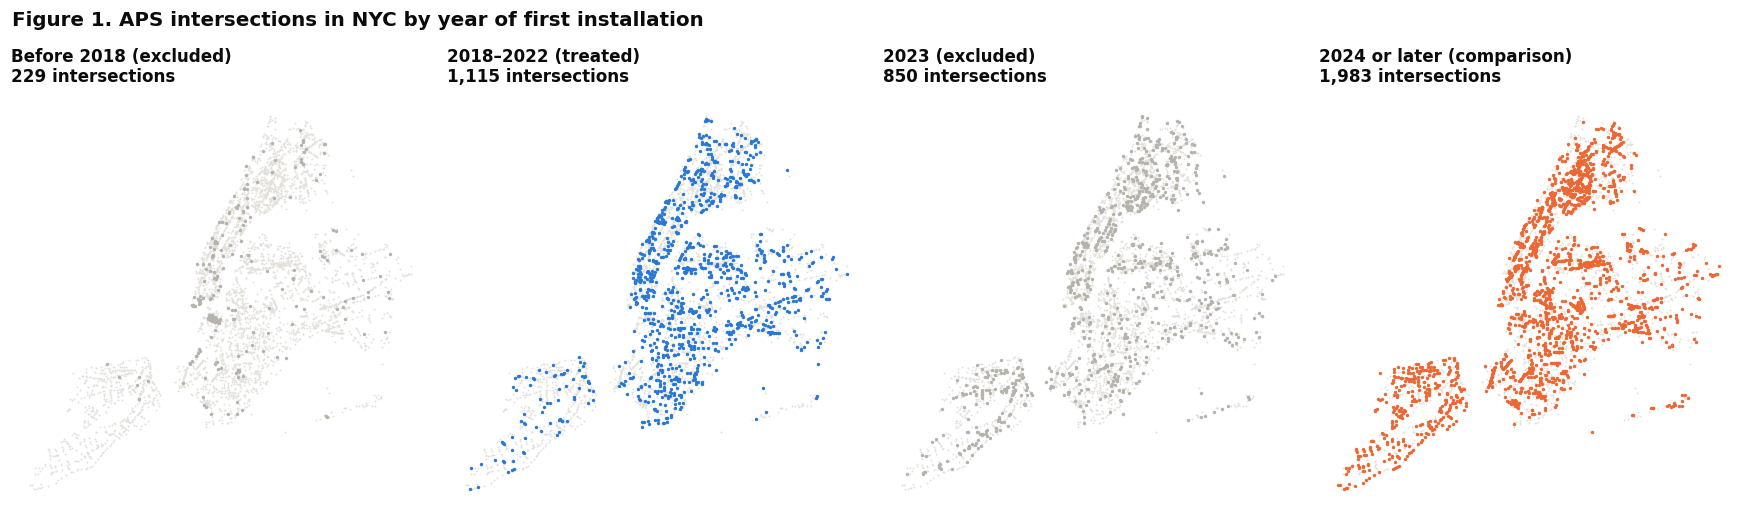

Treated intersections by borough and install year:
install_year   2018  2019  2020  2021  2022  Total
borough                                           
BRONX             4    31    20    32    95    182
BROOKLYN         14    23    68    83   138    326
MANHATTAN        40    40    27    25    70    202
QUEENS           13    46    68    65   135    327
STATEN ISLAND     1    10     8     5    54     78
Total            72   150   191   210   492   1115


In [ ]:
periods = [
    ("Before 2018 (excluded)",    inter.install_year < 2018,               C_OTHER),
    ("2018–2022 (treated)",       inter.install_year.between(2018, 2022), C_TREAT),
    ("2023 (excluded)",           inter.install_year == 2023,              C_OTHER),
    ("2024 or later (comparison)", inter.install_year >= 2024,             C_COMP),
]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.8))
for ax, (title, mask, color) in zip(axes, periods):
    ax.scatter(inter.lon, inter.lat, s=1.5, color="#e1e0d9", linewidths=0)
    ax.scatter(inter.lon[mask], inter.lat[mask], s=5, color=color, linewidths=0)
    ax.set_title(f"{title}\n{mask.sum():,} intersections", fontsize=11, pad=10)
    ax.set_aspect(1 / np.cos(np.radians(40.7)))   # so NYC isn't stretched
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Figure 1. APS intersections in NYC by year of first installation",
             x=0.01, y=0.98, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig("figures/fig1_aps_map_by_period.png")
plt.show()

# Table: treated intersections by borough and install year (to describe where the rollout happened)
by_boro_year = pd.crosstab(panel.drop_duplicates("intersection_id").query("group == 'treated'").borough,
                           panel.drop_duplicates("intersection_id").query("group == 'treated'").install_year,
                           margins=True, margins_name="Total")
print("Treated intersections by borough and install year:")
print(by_boro_year.to_string())


### Figure 1.2: Map of study intersections only (treated vs. comparison)

A simpler version of Figure 1 for the slides, showing only the two groups that are in the study. The light gray dots show all APS intersections, for reference. Intersections whose first APS was installed before 2018 or in 2023 are left out: those installed before 2018 have little or no injury data before installation (the data starts April 2016), and those installed in 2023 have no injury data after installation (the install year is dropped and the data ends December 2023).


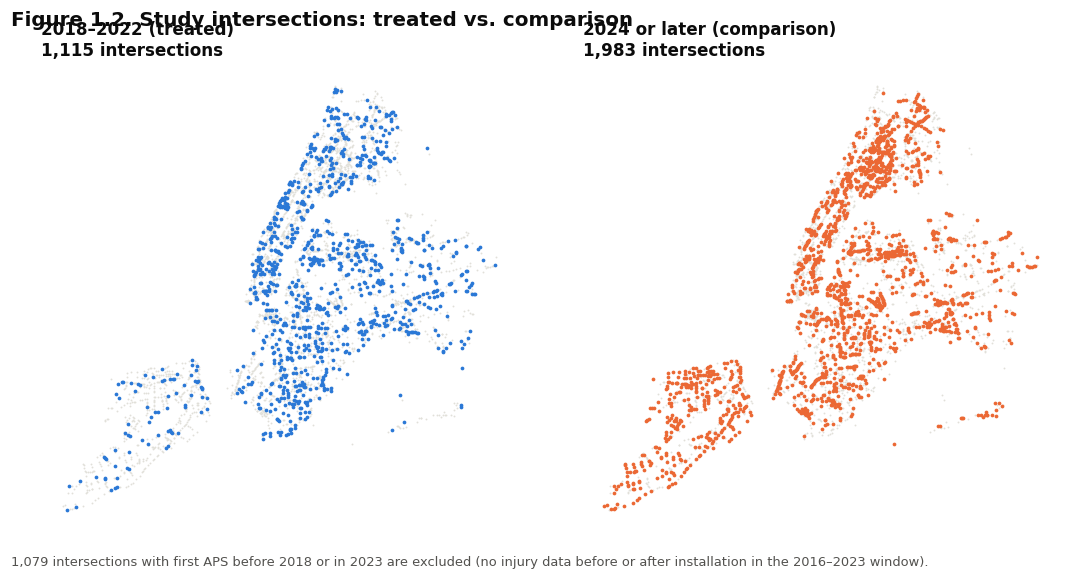

In [ ]:
study_periods = [
    ("2018–2022 (treated)",        inter.install_year.between(2018, 2022), C_TREAT),
    ("2024 or later (comparison)", inter.install_year >= 2024,             C_COMP),
]
n_excl = (~(inter.install_year.between(2018, 2022) | (inter.install_year >= 2024))).sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 5.2))
for ax, (title, mask, color) in zip(axes, study_periods):
    ax.scatter(inter.lon, inter.lat, s=1.5, color="#e1e0d9", linewidths=0)
    ax.scatter(inter.lon[mask], inter.lat[mask], s=6, color=color, linewidths=0)
    ax.set_title(f"{title}\n{mask.sum():,} intersections", fontsize=11)
    ax.set_aspect(1 / np.cos(np.radians(40.7)))   # so NYC isn't stretched
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Figure 1.2. Study intersections: treated vs. comparison",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.01, f"{n_excl:,} intersections with first APS before 2018 or in 2023 are excluded "
         "(no injury data before or after installation in the 2016–2023 window).",
         fontsize=8.5, color=INK_2)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig("figures/fig1_2_aps_map_study_groups.png")
plt.show()

### Figure 2: APS installs per year

The number of intersections receiving their first APS each year. Bars are colored by the role that year plays in the design. Installs speed up sharply after 2021, so the treated group is weighted toward the 2022 cohort, which has only one post-installation year (2023) in the study window.

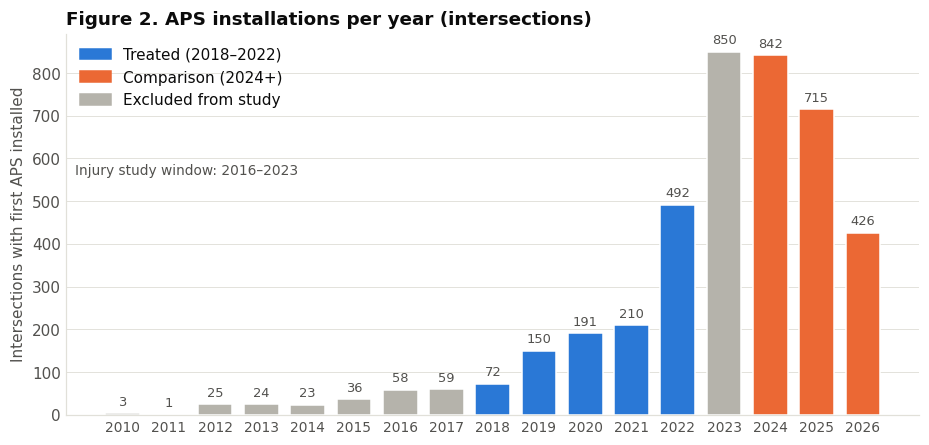

install_year   2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
intersections     3     1    25    24    23    36    58    59    72   150   191   210   492   850   842   715   426


In [ ]:
per_year_int = inter.install_year.value_counts().sort_index()
colors = [C_TREAT if 2018 <= y <= 2022 else C_COMP if y >= 2024 else C_OTHER for y in per_year_int.index]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(per_year_int.index, per_year_int.values, color=colors, width=0.75, edgecolor="white", linewidth=1)
for y, n in per_year_int.items():
    ax.text(y, n + 12, f"{n:,}", ha="center", va="bottom", fontsize=8.5, color=INK_2)
ax.set_xticks(per_year_int.index)
ax.tick_params(axis="x", labelsize=9)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Intersections with first APS installed")
ax.set_title("Figure 2. APS installations per year (intersections)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (C_TREAT, C_COMP, C_OTHER)]
ax.legend(handles, ["Treated (2018–2022)", "Comparison (2024+)", "Excluded from study"], loc="upper left")
ax.text(0.01, 0.66, "Injury study window: 2016–2023", transform=ax.transAxes,
        ha="left", va="top", fontsize=9, color=INK_2)
fig.savefig("figures/fig2_installs_per_year.png")
plt.show()

print(per_year_int.to_frame("intersections").T.to_string())

### Figure 3: Injury trends over time, treated vs. comparison

Average pedestrian injuries per intersection in each year. The shaded band is the 2018–2022 rollout window for the treated group. **Note:** 2016 covers April–December only, so it is lower for both groups, and 2020 drops for both because of COVID. The year fixed effects in Model 1 absorb both of these citywide shifts.



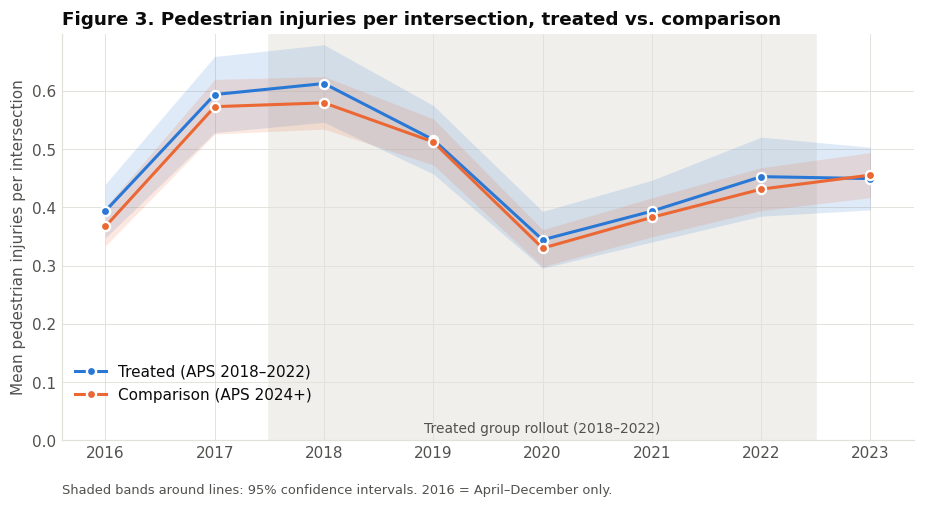

group  comparison  treated
year                      
2016        0.367    0.394
2017        0.573    0.594
2018        0.579    0.613
2019        0.512    0.516
2020        0.330    0.344
2021        0.383    0.393
2022        0.431    0.453
2023        0.455    0.449


In [ ]:
trend = (panel.groupby(["year", "group"]).injuries
         .agg(["mean", "sem", "size"]).reset_index())

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axvspan(2017.5, 2022.5, color="#f0efec", zorder=0)
ax.text(2020, 0.02, "Treated group rollout (2018–2022)", ha="center", fontsize=9, color=INK_2,
        transform=ax.get_xaxis_transform())
for g, color, label in [("treated", C_TREAT, "Treated (APS 2018–2022)"),
                        ("comparison", C_COMP, "Comparison (APS 2024+)")]:
    t = trend[trend.group == g]
    ax.fill_between(t.year, t["mean"] - 1.96 * t["sem"], t["mean"] + 1.96 * t["sem"],
                    color=color, alpha=0.15, linewidth=0)
    ax.plot(t.year, t["mean"], color=color, lw=2, marker="o", ms=6,
            markeredgecolor="white", markeredgewidth=1.5, label=label)
ax.set_xlim(2015.6, 2023.4)
ax.set_ylim(bottom=0)
ax.set_xticks(YEARS)
ax.set_ylabel("Mean pedestrian injuries per intersection")
ax.set_title("Figure 3. Pedestrian injuries per intersection, treated vs. comparison")
ax.legend(loc="lower left", bbox_to_anchor=(0, 0.06))
ax.text(0, -0.13, "Shaded bands around lines: 95% confidence intervals. 2016 = April–December only.",
        transform=ax.transAxes, fontsize=8.5, color=INK_2)
fig.savefig("figures/fig3_injury_trends_by_group.png")
plt.show()

print(trend.pivot(index="year", columns="group", values="mean").round(3).to_string())

### Figure 4: Parallel pre-trends check (event-time plot)

Figure 3 mixes years before and after installation for the treated group. To check the key assumption directly, we line up each treated intersection by **years since its APS was installed** (0 = the install year, which is dropped). For each treated intersection-year we take its injuries **minus the comparison-group average in the same calendar year**, which removes citywide changes like COVID.

**How to read it:** if trends were parallel before installation, the points to the left of 0 should sit on a roughly flat line (they don't need to be at zero, since treated intersections can simply be busier; they just shouldn't trend up or down). Points to the right of 0 are a first, unadjusted look at the APS effect; the real estimate comes from Model 1.

Event times at the far ends (−6, +5) come from only one install cohort each, so they are noisier.

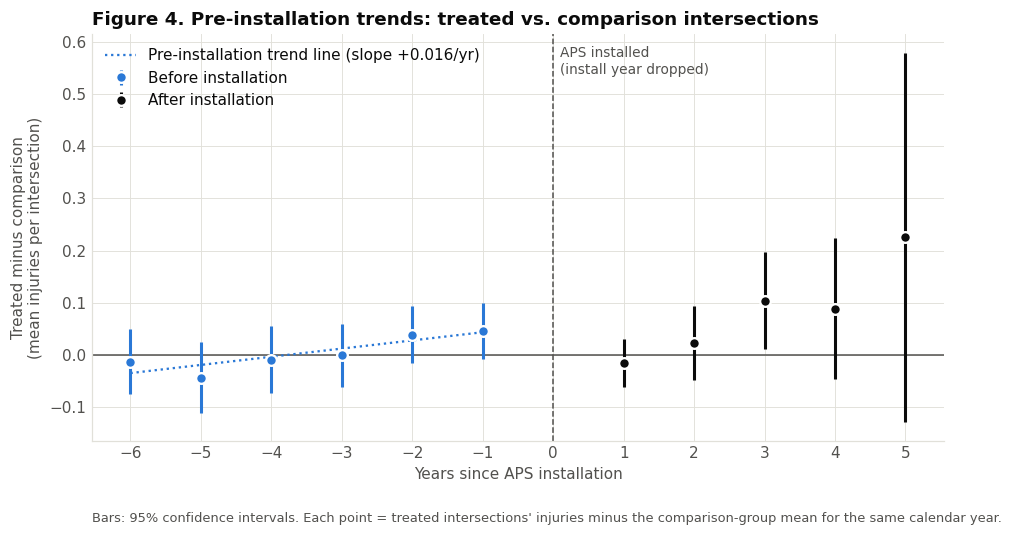

 rel_year   mean   sem  size  n_cohorts
       -6 -0.013 0.032   492          1
       -5 -0.044 0.035   702          2
       -4 -0.010 0.033   893          3
       -3 -0.001 0.031  1043          4
       -2  0.039 0.028  1115          5
       -1  0.045 0.028  1115          5
        1 -0.016 0.023  1115          5
        2  0.022 0.036   623          4
        3  0.104 0.048   413          3
        4  0.089 0.069   222          2
        5  0.225 0.181    72          1


In [ ]:
comp_mean = panel[panel.group == "comparison"].groupby("year").injuries.mean()
tr = panel[panel.group == "treated"].copy()
tr["rel_year"] = tr.year - tr.install_year
tr["diff"] = tr.injuries - tr.year.map(comp_mean)
ev = tr.groupby("rel_year")["diff"].agg(["mean", "sem", "size"]).reset_index()
ev["n_cohorts"] = tr.groupby("rel_year").install_year.nunique().values

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axhline(0, color=INK_2, lw=1)
ax.axvline(0, color=INK_2, lw=1, ls="--")
ax.text(0.1, 0.97, "APS installed\n(install year dropped)", transform=ax.get_xaxis_transform(),
        va="top", fontsize=9, color=INK_2)
pre, post = ev[ev.rel_year < 0], ev[ev.rel_year > 0]
for d, color, label in [(pre, C_TREAT, "Before installation"), (post, INK, "After installation")]:
    ax.errorbar(d.rel_year, d["mean"], yerr=1.96 * d["sem"], fmt="o", color=color, ms=7,
                capsize=0, elinewidth=2, markeredgecolor="white", markeredgewidth=1.5, label=label)
# straight-line fit through the pre-installation points, to show whether they trend
b, a = np.polyfit(pre.rel_year, pre["mean"], 1, w=1 / pre["sem"])
xs = np.array([pre.rel_year.min(), -1])
ax.plot(xs, a + b * xs, color=C_TREAT, lw=1.5, ls=":", label=f"Pre-installation trend line (slope {b:+.3f}/yr)")
ax.set_xticks(range(int(ev.rel_year.min()), int(ev.rel_year.max()) + 1))
ax.set_xlabel("Years since APS installation")
ax.set_ylabel("Treated minus comparison\n(mean injuries per intersection)")
ax.set_title("Figure 4. Pre-installation trends: treated vs. comparison intersections")
ax.legend(loc="upper left")
ax.text(0, -0.2, "Bars: 95% confidence intervals. Each point = treated intersections' injuries minus the "
        "comparison-group mean for the same calendar year.", transform=ax.transAxes, fontsize=8.5, color=INK_2)
fig.savefig("figures/fig4_pretrends_event_time.png")
plt.show()

print(ev.round(3).to_string(index=False))

**Formal pre-trend tests.** We test the same question two ways. **(1) Calendar time:** we keep only **pre-installation** data (all comparison rows, plus treated rows before their install year) and regress injuries on year dummies, the treated flag, and a treated × year trend. The `treated:year_c` coefficient asks: *before APS, were injuries at treated intersections trending differently from comparison intersections?* A small, non-significant coefficient supports parallel trends. **(2) Event time:** among treated rows before installation, we regress the Figure 4 gap on years-since-install, which asks whether the gap grows as installation approaches. Standard errors are clustered by intersection, because the same intersection appears in several years.

**If the event-time slope is positive and significant**, injuries were rising at treated intersections just before APS went in. That would fit DOT choosing intersections after a recent rise in crashes. Any drop afterwards could then be partly **regression to the mean** rather than an APS effect, so it should be noted on Slide 4, in Model 1, and in the limitations.

In [ ]:
pre_df = panel[(panel.group == "comparison") | (panel.year < panel.install_year)].copy()
pre_df["year_c"] = pre_df.year - 2016
pt = smf.ols("injuries ~ C(year) + treated + treated:year_c", data=pre_df).fit(
    cov_type="cluster", cov_kwds={"groups": pre_df.intersection_id})
coef, se, p = pt.params["treated:year_c"], pt.bse["treated:year_c"], pt.pvalues["treated:year_c"]
ci = pt.conf_int().loc["treated:year_c"]
print(f"Pre-installation rows used: {len(pre_df):,}")
print(f"Treated x year trend difference: {coef:+.4f} injuries per intersection per year "
      f"(95% CI {ci[0]:+.4f} to {ci[1]:+.4f}, p = {p:.3f})")
print(f"Treated level difference (2016): {pt.params['treated']:+.3f} (p = {pt.pvalues['treated']:.3f})")

# Same question on the event-time scale used in Figure 4: among treated rows before installation,
# does the gap vs. the comparison group grow as installation gets closer?
tr_pre = tr[tr.rel_year < 0]
et = smf.ols("diff ~ rel_year", data=tr_pre).fit(cov_type="cluster", cov_kwds={"groups": tr_pre.intersection_id})
et_coef, et_p, et_ci = et.params["rel_year"], et.pvalues["rel_year"], et.conf_int().loc["rel_year"]
print(f"\nEvent-time pre-trend slope: {et_coef:+.4f} per year closer to install "
      f"(95% CI {et_ci[0]:+.4f} to {et_ci[1]:+.4f}, p = {et_p:.3f})")

pretrend_ok = (p >= 0.05) and (et_p >= 0.05)
print(">>> Pre-trends look", "PARALLEL (neither test is significant)" if pretrend_ok
      else "NOT clearly parallel (at least one test is significant). Flag this for Wenjin and the limitations.")

Pre-installation rows used: 21,224
Treated x year trend difference: -0.0128 injuries per intersection per year (95% CI -0.0281 to +0.0026, p = 0.103)
Treated level difference (2016): +0.035 (p = 0.259)

Event-time pre-trend slope: +0.0174 per year closer to install (95% CI +0.0029 to +0.0319, p = 0.019)
>>> Pre-trends look NOT clearly parallel (at least one test is significant). Flag this for Wenjin and the limitations.


### Figure 5: When LPIs were installed relative to APS

A **Leading Pedestrian Interval (LPI)** gives pedestrians a few seconds of WALK before cars get a green light. LPIs are another pedestrian-safety change, and DOT often installed them at the same intersections around the same time as APS. If so, part of any change after APS could really be the LPI. This figure shows, for each treated intersection with a dated LPI within 100 ft, the **LPI install year minus the APS install year**: 0 = same year, negative = the LPI came first, positive = the LPI came later. Blue bars are within one year of the APS.

This uses the intersection table (`inter`), which keeps the actual LPI install year. The panel drops the APS install year, so it would place a same-year LPI one year late.

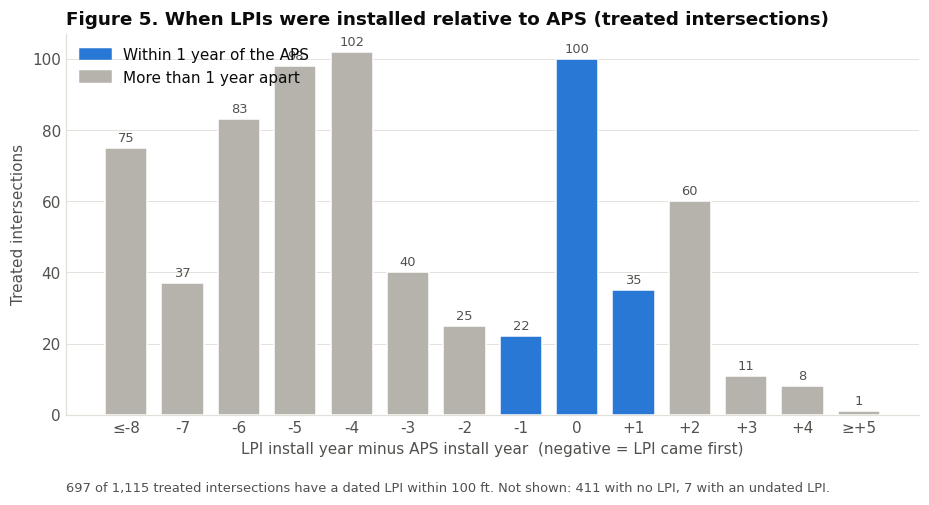

Treated intersections with a dated LPI: 697 of 1,115
  LPI in the same year as APS:     14.3%
  LPI within 1 year of APS:        22.5%
  LPI more than 1 year BEFORE APS: 66.0%
  LPI more than 1 year AFTER APS:  11.5%

Full distribution of the gap (years):
               -40  -39  -38  -37  -31  -29  -26  -25  -24  -23  -22  -21  -20  -19  -18  -17  -16  -15  -14  -13  -12  -11  -10  -9   -8   -7   -6   -5   -4   -3   -2   -1    0    1    2    3    4    5 
intersections    1    1    1    1    1    1    1    2    1    1    2    3    4    2    3    2   10    5    2    1    4    6    8    4    8   37   83   98  102   40   25   22  100   35   60   11    8    1


In [ ]:
tr_int = inter[inter.install_year.between(2018, 2022)].copy()   # treated intersections
n_tr       = len(tr_int)
n_no_lpi   = int((tr_int.lpi == 0).sum())
n_undated  = int(((tr_int.lpi == 1) & tr_int.lpi_year.isna()).sum())
has_date   = (tr_int.lpi == 1) & tr_int.lpi_year.notna()
gap = (tr_int.loc[has_date, "lpi_year"] - tr_int.loc[has_date, "install_year"]).round().astype(int)

if len(gap) == 0:
    print("No treated intersections have a dated LPI, so Figure 5 can't be drawn.")
    lpi_same = lpi_within1 = lpi_before = lpi_after = np.nan
else:
    LO, HI = -8, 5                      # gaps further out are grouped into the end bars
    counts = gap.clip(LO, HI).value_counts().reindex(range(LO, HI + 1), fill_value=0)
    colors = [C_TREAT if abs(g) <= 1 else C_OTHER for g in counts.index]

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(counts.index, counts.values, color=colors, width=0.75, edgecolor="white", linewidth=1)
    for g, n in counts.items():
        if n:
            ax.text(g, n + counts.max() * 0.01, f"{n:,}", ha="center", va="bottom", fontsize=8.5, color=INK_2)
    labels = [f"≤{LO}" if g == LO else f"≥+{HI}" if g == HI else ("0" if g == 0 else f"{g:+d}")
              for g in counts.index]
    ax.set_xticks(counts.index)
    ax.set_xticklabels(labels)
    ax.grid(axis="x", visible=False)
    ax.set_xlabel("LPI install year minus APS install year  (negative = LPI came first)")
    ax.set_ylabel("Treated intersections")
    ax.set_title("Figure 5. When LPIs were installed relative to APS (treated intersections)")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (C_TREAT, C_OTHER)]
    ax.legend(handles, ["Within 1 year of the APS", "More than 1 year apart"], loc="upper left")
    ax.text(0, -0.2, f"{has_date.sum():,} of {n_tr:,} treated intersections have a dated LPI within 100 ft. "
            f"Not shown: {n_no_lpi:,} with no LPI, {n_undated:,} with an undated LPI.",
            transform=ax.transAxes, fontsize=8.5, color=INK_2)
    fig.savefig("figures/fig5_lpi_timing_vs_aps.png")
    plt.show()

    lpi_same, lpi_within1 = (gap == 0).mean(), (gap.abs() <= 1).mean()
    lpi_before, lpi_after = (gap < -1).mean(), (gap > 1).mean()
    print(f"Treated intersections with a dated LPI: {len(gap):,} of {n_tr:,}")
    print(f"  LPI in the same year as APS:     {lpi_same:.1%}")
    print(f"  LPI within 1 year of APS:        {lpi_within1:.1%}")
    print(f"  LPI more than 1 year BEFORE APS: {lpi_before:.1%}")
    print(f"  LPI more than 1 year AFTER APS:  {lpi_after:.1%}")
    print("\nFull distribution of the gap (years):")
    print(gap.value_counts().sort_index().to_frame("intersections").T.to_string())

### Table 1: Descriptive statistics for the panel

One column for the whole panel and one per group. For the treated group, we also split rows into before and after installation. Count variables show the mean per intersection-year with the standard deviation in brackets.

In [ ]:
def describe(d):
    ints = d.drop_duplicates("intersection_id")
    row = {
        "Intersections": f"{d.intersection_id.nunique():,}",
        "Intersection-years": f"{len(d):,}",
    }
    for col, name in [("injuries", "Pedestrian injuries"), ("injuries_65plus", "Injuries, age 65+"),
                      ("injuries_night", "Injuries, night (6pm–6am)"), ("killed", "Pedestrians killed")]:
        row[f"{name}: mean (SD)"] = f"{d[col].mean():.3f} ({d[col].std():.3f})"
    row["Injuries: median [max]"] = f"{d.injuries.median():.0f} [{d.injuries.max():.0f}]"
    row["Total injuries"] = f"{d.injuries.sum():,}"
    row["Share of years with any injury"] = f"{d.any_injury.mean():.1%}"
    row["Share of years with zero injuries"] = f"{1 - d.any_injury.mean():.1%}"
    row["Has LPI within 100 ft"] = f"{ints.LPI.mean():.1%}"
    row["LPI active (intersection-years)"] = f"{d.LPI_active.mean():.1%}"
    row["Has Barnes Dance within 100 ft"] = f"{ints.barnes_dance.mean():.1%}"
    for b in ["MANHATTAN", "BROOKLYN", "QUEENS", "BRONX", "STATEN ISLAND"]:
        row[f"Borough: {b.title()}"] = f"{(ints.borough == b).mean():.1%}"
    return pd.Series(row)

treated_rows = panel[panel.group == "treated"]
desc = pd.DataFrame({
    "All": describe(panel),
    "Treated": describe(treated_rows),
    "Treated, before APS": describe(treated_rows[treated_rows.APS_active == 0]),
    "Treated, after APS": describe(treated_rows[treated_rows.APS_active == 1]),
    "Comparison": describe(panel[panel.group == "comparison"]),
})
desc.to_csv("tables/table1_descriptives.csv")
print(desc.to_string())
if (panel.borough == "UNKNOWN").any():
    print(f"\nNote: {panel[panel.borough == 'UNKNOWN'].intersection_id.nunique()} intersections have an unknown borough.")

                                                All        Treated Treated, before APS Treated, after APS     Comparison
Intersections                                 3,098          1,115               1,115              1,115          1,983
Intersection-years                           23,669          7,805               5,360              2,445         15,864
Pedestrian injuries: mean (SD)        0.460 (0.898)  0.473 (0.931)       0.481 (0.946)      0.458 (0.897)  0.454 (0.881)
Injuries, age 65+: mean (SD)          0.064 (0.271)  0.071 (0.297)       0.070 (0.297)      0.072 (0.296)  0.060 (0.258)
Injuries, night (6pm–6am): mean (SD)  0.187 (0.519)  0.192 (0.529)       0.198 (0.542)      0.179 (0.500)  0.185 (0.513)
Pedestrians killed: mean (SD)         0.006 (0.082)  0.006 (0.081)       0.006 (0.081)      0.007 (0.081)  0.006 (0.083)
Injuries: median [max]                       0 [10]          0 [9]               0 [9]              0 [9]         0 [10]
Total injuries                  

### Bivariate test 1: Chi-square, APS active × any injury

Is having an active APS associated with whether an intersection-year has **any** pedestrian injury? We run it on the whole panel and then only within the treated group (before vs. after installation at the same intersections).

**Caution:** this is a simple association test with no controls. APS-active years are concentrated in 2021–2023, so citywide trends (like the post-COVID rebound) are mixed in. LPIs were also often added around the same time as APS (Figure 5 and the test below), so this test cannot separate the two. Model 1 handles both: year and intersection fixed effects for the trends, and `LPI_active` as a control for the LPIs.

In [ ]:
def chi_square(d, label):
    tab = pd.crosstab(d.APS_active, d.any_injury)
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    share = d.groupby("APS_active").any_injury.mean()
    print(f"--- {label} ---")
    print(tab.rename(index={0: "APS not active", 1: "APS active"},
                     columns={0: "no injury", 1: "any injury"}).to_string())
    print(f"Share with any injury: APS not active {share[0]:.1%} | APS active {share[1]:.1%}")
    print(f"Chi-square = {chi2:.2f}, df = {dof}, p = {p:.4f}, Cramér's V = {v:.3f}\n")
    return {"sample": label, "n": len(d), "pct_any_not_active": share[0], "pct_any_active": share[1],
            "chi2": chi2, "df": dof, "p_value": p, "cramers_v": v}

chi_results = pd.DataFrame([chi_square(panel, "Full panel"),
                            chi_square(treated_rows, "Treated intersections only (before vs. after)")])

--- Full panel ---
any_injury      no injury  any injury
APS_active                           
APS not active      14962        6262
APS active           1746         699
Share with any injury: APS not active 29.5% | APS active 28.6%
Chi-square = 0.84, df = 1, p = 0.3590, Cramér's V = 0.006

--- Treated intersections only (before vs. after) ---
any_injury      no injury  any injury
APS_active                           
APS not active       3782        1578
APS active           1746         699
Share with any injury: APS not active 29.4% | APS active 28.6%
Chi-square = 0.55, df = 1, p = 0.4589, Cramér's V = 0.008



### Bivariate test 1b: Chi-square, APS active × LPI active

Are intersection-years with an active APS also more likely to have an active LPI? A significant result means the two overlap, so a simple before/after comparison mixes their effects. That is why Model 1 includes `LPI_active` as a control. We run it on the whole panel and within the treated group only.

**Caution:** LPIs were also spreading citywide during 2016–2023, so later years have more LPIs everywhere. Part of the overlap is just both happening in later years; Figure 5 shows the timing at the same intersection more directly.

In [ ]:
def chi_square_lpi(d, label):
    tab = pd.crosstab(d.APS_active, d.LPI_active)
    if tab.shape != (2, 2):
        print(f"--- {label} --- skipped: APS_active or LPI_active has only one value here\n")
        return None
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    share = d.groupby("APS_active").LPI_active.mean()
    print(f"--- {label} ---")
    print(tab.rename(index={0: "APS not active", 1: "APS active"},
                     columns={0: "LPI not active", 1: "LPI active"}).to_string())
    print(f"Share with LPI active: APS not active {share[0]:.1%} | APS active {share[1]:.1%}")
    print(f"Chi-square = {chi2:.2f}, df = {dof}, p = {p:.4g}, Cramér's V = {v:.3f}\n")
    return {"sample": label, "n": len(d), "pct_lpi_aps_not_active": share[0], "pct_lpi_aps_active": share[1],
            "chi2": chi2, "df": dof, "p_value": p, "cramers_v": v}

lpi_chi = pd.DataFrame([r for r in [chi_square_lpi(panel, "Full panel"),
                                    chi_square_lpi(treated_rows, "Treated intersections only (before vs. after)")]
                        if r is not None])
lpi_chi.to_csv("tables/table2b_chi_square_aps_lpi.csv", index=False)

--- Full panel ---
LPI_active      LPI not active  LPI active
APS_active                                
APS not active           13662        7562
APS active                 958        1487
Share with LPI active: APS not active 35.6% | APS active 60.8%
Chi-square = 587.97, df = 1, p = 6.919e-130, Cramér's V = 0.158

--- Treated intersections only (before vs. after) ---
LPI_active      LPI not active  LPI active
APS_active                                
APS not active            3427        1933
APS active                 958        1487
Share with LPI active: APS not active 36.1% | APS active 60.8%
Chi-square = 416.95, df = 1, p = 1.124e-92, Cramér's V = 0.231



### Bivariate test 2: ANOVA, injuries by borough and by group

The same intersection appears in up to 8 years, so its yearly rows aren't independent. To keep the ANOVA honest, we first average each intersection's injuries across its years, so **each intersection counts once**.

* **By borough:** do some boroughs have more injuries per APS intersection?
* **By group:** were treated and comparison intersections similar *before* any treatment? We use 2016–2017 only, when no study intersection had an APS yet. A big baseline gap isn't fatal (intersection fixed effects absorb fixed differences), but it's worth reporting.

Injury counts are skewed (most are 0), so we also report the Kruskal–Wallis test, which doesn't assume normality, as a check.

In [ ]:
def anova(d, by, label):
    groups = {k: v.values for k, v in d.groupby(by).injuries}
    F, p = stats.f_oneway(*groups.values())
    H, p_kw = stats.kruskal(*groups.values())
    grand = d.injuries.mean()
    ss_between = sum(len(v) * (v.mean() - grand) ** 2 for v in groups.values())
    eta2 = ss_between / ((d.injuries - grand) ** 2).sum()
    print(f"--- {label} ---")
    print(d.groupby(by).injuries.agg(intersections="size", mean="mean", sd="std", median="median")
          .round(3).to_string())
    print(f"ANOVA: F = {F:.2f}, p = {p:.4g}, eta-squared = {eta2:.3f}")
    print(f"Kruskal-Wallis: H = {H:.2f}, p = {p_kw:.4g}\n")
    return {"test": label, "F": F, "p_value": p, "eta_sq": eta2, "kruskal_H": H, "kruskal_p": p_kw}

int_means = (panel[panel.borough != "UNKNOWN"]
             .groupby(["intersection_id", "borough", "group"]).injuries.mean().reset_index())
baseline = (panel[panel.year.isin([2016, 2017])]
            .groupby(["intersection_id", "group"]).injuries.mean().reset_index())

anova_results = pd.DataFrame([
    anova(int_means, "borough", "Mean yearly injuries by borough (all years)"),
    anova(baseline, "group", "Baseline injuries (2016–2017) by group"),
])

# Tukey post-hoc: which boroughs differ from each other?
from statsmodels.stats.multicomp import pairwise_tukeyhsd
print(pairwise_tukeyhsd(int_means.injuries, int_means.borough).summary())

chi_results.to_csv("tables/table2_chi_square.csv", index=False)
anova_results.to_csv("tables/table3_anova.csv", index=False)

--- Mean yearly injuries by borough (all years) ---
               intersections   mean     sd  median
borough                                           
BRONX                    573  0.525  0.585   0.375
BROOKLYN                 839  0.483  0.624   0.286
MANHATTAN                488  0.620  0.663   0.429
QUEENS                   785  0.405  0.514   0.250
STATEN ISLAND            413  0.243  0.376   0.125
ANOVA: F = 28.71, p = 1.842e-23, eta-squared = 0.036
Kruskal-Wallis: H = 181.52, p = 3.513e-38

--- Baseline injuries (2016–2017) by group ---
            intersections   mean     sd  median
group                                          
comparison           1983  0.470  0.754     0.0
treated              1115  0.494  0.811     0.0
ANOVA: F = 0.67, p = 0.4135, eta-squared = 0.000
Kruskal-Wallis: H = 0.07, p = 0.7952

     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1      group2    meandiff p-adj   lower   upper  reject
-------------------------------------------

### Summary numbers for Slide 4 and the report (auto-filled)

In [ ]:
b_means = int_means.groupby("borough").injuries.mean().sort_values(ascending=False)
c_full, c_tr = chi_results.iloc[0], chi_results.iloc[1]
a_boro, a_grp = anova_results.iloc[0], anova_results.iloc[1]
lpi_chi_lines = "\n".join(
    f"  Chi-square APS active x LPI active ({r.sample}): LPI active in {r.pct_lpi_aps_not_active:.1%} of APS-off years "
    f"vs {r.pct_lpi_aps_active:.1%} of APS-on years, chi2 = {r.chi2:.2f}, p = {r.p_value:.3g}, Cramer's V = {r.cramers_v:.3f}."
    for r in lpi_chi.itertuples())
print(f'''EXPLORATORY ANALYSIS SUMMARY (Person 3)
- Installs: {len(inter):,} APS intersections; installs grew from {per_year_int.get(2018, 0)} in 2018 to {per_year_int.get(2022, 0)} in 2022 and {per_year_int.get(2023, 0)} in 2023.
  Treated (2018-2022): {(panel.group == "treated").groupby(panel.intersection_id).first().sum():,} intersections; comparison (2024+): {(panel.group == "comparison").groupby(panel.intersection_id).first().sum():,}.
- Panel: {len(panel):,} intersection-years; mean {panel.injuries.mean():.3f} injuries per intersection-year; {1 - panel.any_injury.mean():.1%} have zero injuries.
- Trends: both groups dip in 2020 (COVID) and move together over time (Figure 3).
- Pre-trends (calendar time): treated-minus-comparison gap changed by {coef:+.4f} injuries/yr (95% CI {ci[0]:+.4f} to {ci[1]:+.4f}, p = {p:.3f}).
- Pre-trends (event time, Figure 4): gap changed by {et_coef:+.4f} per year closer to install (95% CI {et_ci[0]:+.4f} to {et_ci[1]:+.4f}, p = {et_p:.3f}).
  -> {"Consistent with parallel trends." if pretrend_ok else "Not clearly parallel: injuries were creeping up at treated intersections in the years just before APS, which suggests DOT may have targeted intersections with rising injuries. A post-install drop could partly be regression to the mean. Flag for Model 1 and the limitations."}
- Chi-square (APS active x any injury, full panel): {c_full.pct_any_not_active:.1%} vs {c_full.pct_any_active:.1%}, chi2 = {c_full.chi2:.2f}, p = {c_full.p_value:.3g}, Cramer's V = {c_full.cramers_v:.3f}.
  Treated only, before vs after: {c_tr.pct_any_not_active:.1%} vs {c_tr.pct_any_active:.1%}, chi2 = {c_tr.chi2:.2f}, p = {c_tr.p_value:.3g}.
- LPI timing (Figure 5): among treated intersections with a dated LPI, {lpi_same:.1%} got it the same year as APS and {lpi_within1:.1%} within 1 year; {lpi_before:.1%} had it more than a year before, {lpi_after:.1%} more than a year after.
{lpi_chi_lines}
  -> APS and LPI overlap, so Model 1 should control for LPI_active.
- ANOVA by borough: F = {a_boro.F:.2f}, p = {a_boro.p_value:.3g}, eta^2 = {a_boro.eta_sq:.3f}. Highest: {b_means.index[0].title()} ({b_means.iloc[0]:.2f}/yr); lowest: {b_means.index[-1].title()} ({b_means.iloc[-1]:.2f}/yr).
- ANOVA by group at baseline (2016-2017): F = {a_grp.F:.2f}, p = {a_grp.p_value:.3g} (fixed differences are absorbed by intersection fixed effects).
- Files: figures/fig1, fig1_2, fig2-fig5 (PNG), tables/table1_descriptives.csv, table2_chi_square.csv, table2b_chi_square_aps_lpi.csv, table3_anova.csv.
APS and LPI overlap substantially: at treated intersections, LPI was active in 60.8% of post-APS years vs. 36.1% of pre-APS years (χ² = 416.95, p < 0.001, Cramér's V = 0.23). However, most of this overlap reflects LPIs accumulating over time rather than joint installation: of 697 treated intersections with a dated LPI, 66% received it more than a year before their APS and only 14% in the same year (Figure 5). Because the two interventions mostly switched on in different years, Model 1 can control for LPI_active and estimate the APS effect net of LPIs. Raw injury rates did not differ by APS status (29.5% vs. 28.6%, χ² = 0.84, p = 0.36)''')


EXPLORATORY ANALYSIS SUMMARY (Person 3)
- Installs: 4,177 APS intersections; installs grew from 72 in 2018 to 492 in 2022 and 850 in 2023.
  Treated (2018-2022): 1,115 intersections; comparison (2024+): 1,983.
- Panel: 23,669 intersection-years; mean 0.460 injuries per intersection-year; 70.6% have zero injuries.
- Trends: both groups dip in 2020 (COVID) and move together over time (Figure 3).
- Pre-trends (calendar time): treated-minus-comparison gap changed by -0.0128 injuries/yr (95% CI -0.0281 to +0.0026, p = 0.103).
- Pre-trends (event time, Figure 4): gap changed by +0.0174 per year closer to install (95% CI +0.0029 to +0.0319, p = 0.019).
  -> Not clearly parallel: injuries were creeping up at treated intersections in the years just before APS, which suggests DOT may have targeted intersections with rising injuries. A post-install drop could partly be regression to the mean. Flag for Model 1 and the limitations.
- Chi-square (APS active x any injury, full panel): 29.5% vs 28.6%,

APS and LPI overlap substantially: at treated intersections, LPI was active in 60.8% of post-APS years vs. 36.1% of pre-APS years (χ² = 416.95, p < 0.001, Cramér's V = 0.23). However, most of this overlap reflects LPIs accumulating over time rather than joint installation: of 697 treated intersections with a dated LPI, 66% received it more than a year before their APS and only 14% in the same year (Figure 5). Because the two interventions mostly switched on in different years, Model 1 can control for LPI_active and estimate the APS effect net of LPIs. Raw injury rates did not differ by APS status (29.5% vs. 28.6%, χ² = 0.84, p = 0.36)

In [ ]:
# Download the figures and tables
import shutil
shutil.make_archive("sabria_eda_outputs", "zip", root_dir=".", base_dir="figures")
shutil.make_archive("sabria_eda_tables", "zip", root_dir=".", base_dir="tables")
from google.colab import files
files.download("sabria_eda_outputs.zip")
files.download("sabria_eda_tables.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>